Today's topics:

* digitizing a published plot with WebPlotDigitizer
* reading a file with no header row
* linear interpolation with `np.interp`
* resampling data onto an even grid
* interpolation and extrapolation

# Crushing a printed lattice

Today we will turn a published plot into numbers and estimate values between them.

<img src="https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/digitizing_chart.png" alt="Stress-strain curve of a printed lattice in compression, stress in MPa from 0 to 80 against strain from 0 to 0.8, drawn as a blue dashed line. The stress rises to a peak of about 45 MPa near strain 0.08, drops to about 4 MPa near 0.13, then wavers between about 10 and 20 MPa out to strain 0.65. Inset video frames show elastic deformation, shear band deformation, deformation, and the start of densification." width=540/>

*Figure 3 of Al-Saedi and Masood, "Mechanical performance of functionally graded lattice structures made with selective laser melting 3D printing," IOP Conf. Ser.: Mater. Sci. Eng. 433, 012078 (2018), [doi:10.1088/1757-899X/433/1/012078](https://doi.org/10.1088/1757-899X/433/1/012078), [CC BY 3.0](https://creativecommons.org/licenses/by/3.0/).*

Above: An aluminum-silicon (AlSi12) lattice, printed by selective laser melting and crushed in compression.

Lattices like this can absorb energy in a crash.

First the struts bend.
Then a band of cells collapses.
The rest crush at a fairly steady stress.
Near a strain of 0.6 the struts start to touch and the lattice densifies.

The energy absorbed per unit volume is the area under the stress-strain curve.

How much energy does this lattice absorb before it densifies?
The paper gives us only the picture.

# Digitizing a plot

## WebPlotDigitizer

[WebPlotDigitizer](https://apps.automeris.io/wpd4/) reads points off an image of a plot.

1. Save the image above and load it into WebPlotDigitizer.
2. Choose **2D (X-Y) Plot**.
   Click two known points on each axis and type in their values.
   Use 0 and 0.8 for strain.
   Use 0 and 80 for stress.
   If an axis is logarithmic, check **Log scale** here.
3. Pick the line color with the color picker and draw a box around the curve.
4. Run the automatic extraction.
5. Export the points as a CSV file.

The tool measures pixels on the image.
Our numbers can only be as good as the picture and our clicks.

## Reading a file with no header

For the Python examples, we'll use a saved export of this curve.
Here are its first lines:

```
0.0051296043656207,-0.0278107426590423
0.0137981710858671,1.2326194453430477
0.0175132711088298,3.5303549529721465
```

There is no header row with column names.
Let's see what `pandas` does with that:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/digitizing_chart_wpd.csv'
print(pd.read_csv(url).columns)

Index(['0.0051296043656207', '-0.0278107426590423'], dtype='str')


`pandas` used the first row of numbers as the column names.
That point is now missing from the data.

`header=None` says the file has no header.
`names=` gives the columns their names:

In [2]:
curve = pd.read_csv(url, header=None, names=['strain', 'stress_MPa'])
display(curve)

,strain,stress_MPa
0,0.005130,-0.027811
1,0.013798,1.232619
2,0.017513,3.530355
3,0.019990,6.064491
4,0.021848,8.378969
...,...,...
88,0.613168,16.667244
89,0.621836,17.093648
90,0.631743,17.803953
91,0.641650,18.879144


The first stress is slightly negative.
That small error can come from digitizing and calibrating the image.

## Plotting the points

Text(0, 0.5, 'stress (MPa)')

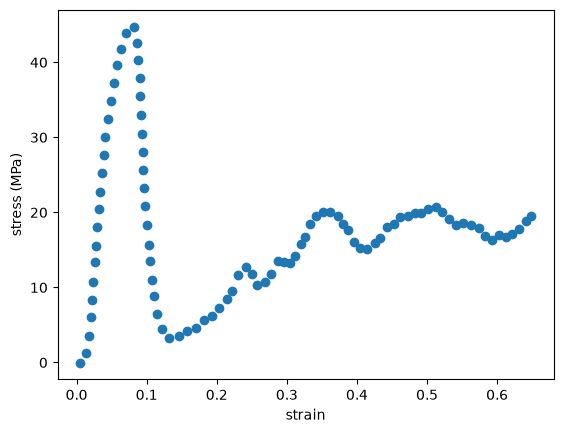

In [3]:
strain = curve['strain']
stress = curve['stress_MPa']

fig, ax = plt.subplots()
ax.plot(strain, stress, 'o')
ax.set_xlabel('strain')
ax.set_ylabel('stress (MPa)')

The points are close together around the peak and farther apart on the plateau.

How many of the 93 points sit below a strain of 0.1?

In [4]:
print(np.sum(strain < 0.1))  # True counts as 1

31


The digitized points are closer together in strain on the steep parts of the curve.

## A first estimate of the energy

The area under a curve is its average height times its width.

Stress in MPa times strain gives energy per volume in MJ/m$^3$.
Let's average the stress of every point up to a strain of 0.6:

In [5]:
before_dense = strain <= 0.6
print(np.mean(stress[before_dense]) * 0.6)  # MJ/m^3

11.012309812361117


About 11 MJ/m$^3$.

But a third of the points sit near the peak, where the stress is highest.
A plain mean counts the peak too heavily.

We want the stress at evenly spaced strains instead.
Most of those strains fall between our points.

# Interpolation

## Between two points

What is the stress at a strain of 0.253?
Here are the points around it:

In [6]:
display(curve[(strain > 0.24) & (strain < 0.27)])

,strain,stress_MPa
48,0.241038,12.755100
49,0.250326,11.752414
50,0.257756,10.334012
51,0.268902,10.720074


**Linear interpolation** draws a straight line between the two neighbors and reads the value off that line.

`np.interp(x_new, x, y)` does this for us.
The known `x` values must be in increasing order.

In [7]:
print(np.interp(0.253, strain, stress))  # MPa

11.241995109018898


11.24 MPa sits between the stresses of its two neighbors, as it should.

## On an even grid

`np.interp` also takes an array of new `x` values.

Let's make 61 evenly spaced strains from 0 to 0.6 and interpolate the stress at each:

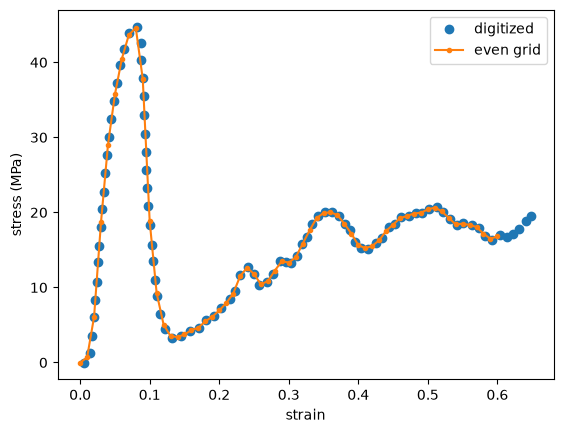

In [8]:
strain_grid = np.linspace(0, 0.6, 61)  # steps of 0.01
stress_grid = np.interp(strain_grid, strain, stress)

fig, ax = plt.subplots()
ax.plot(strain, stress, 'o', label='digitized')
ax.plot(strain_grid, stress_grid, '.-', label='even grid')
ax.set_xlabel('strain')
ax.set_ylabel('stress (MPa)')
ax.legend()

Now every strain counts equally.
Let's repeat the energy estimate with the grid:

In [9]:
print(np.mean(stress_grid) * 0.6)  # MJ/m^3

9.684245450710163


About 9.7 MJ/m$^3$, 12% less than the plain mean.

So up to a strain of 0.6, this lattice absorbs about 9.7 MJ per cubic meter.

### [Check your understanding]

The **plateau stress** is the average stress while the cells crush, here between strains 0.2 and 0.6.

1. Compute it from the digitized points between 0.2 and 0.6.
   The mask `plateau` below selects them.
2. Compute it again from 41 evenly spaced strains between 0.2 and 0.6, using `np.interp`.

How different are the two?
Why did the grid change the energy estimate but not this one?

In [10]:
plateau = (strain >= 0.2) & (strain <= 0.6)

# Outside the data

The digitized curve stops at a strain of 0.65.
What does `np.interp` give at 0.7?

In [11]:
print(np.interp(0.7, strain, stress))
print(stress.iloc[-1])  # the last digitized point

19.528383165937136
19.528383165937136


Outside the data, `np.interp` returns the value at the nearest end.
It gives no error and no warning.

But at 0.7 the lattice is densifying.
Its stress climbs as the struts pack together.

The real stress is likely higher than 19.5 MPa.
We have no measurements beyond this strain to check that estimate.

Estimating between our points is interpolation.
Beyond the last point it is extrapolation.

# Summary

* WebPlotDigitizer turns an image of a plot into a table of points.
* `pd.read_csv(url, header=None, names=[...])` reads a file with no header row.
* `np.interp(x_new, x, y)` estimates `y` by straight lines between known points; `x` must increase.
* Resampling onto an even grid keeps crowded points from dominating an average.
* Outside the data, `np.interp` returns the end value without a warning.

# Quiz 10 warm-up

In Q1 you will:
- read two `dropna` filters and say why a row is removed,
- say what filling missing values with a number would claim about the data.

In Q2 you will:
- read a left merge and say whose rows it keeps,
- say what a count of missing values after a merge includes.

## Further reading

* NumPy, [`numpy.interp`](https://numpy.org/doc/stable/reference/generated/numpy.interp.html)
* WebPlotDigitizer, [user manual](https://automeris.io/docs/)

# Appendix A: from stress back to strain

At what strain does the lattice first reach 30 MPa?

Swapping the arguments, `np.interp(30, stress, strain)`, would need the stresses in increasing order.
They rise to the peak and then fall.
So we keep only the points up to the peak:

In [12]:
peak = np.argmax(stress)  # position of the highest stress
rising = strain <= strain[peak]  # up to and including the peak
print(np.interp(30, stress[rising], strain[rising]))

0.04106250490396169


A strain of about 0.041, on the rising part of the curve before the peak.